# 03 · Gold · XAUUSD

Vérifier les bougies Silver et calculer les variables causales et leur catalogue, en gardant le lien avec leur clôture.

Le mode `SNAPSHOT` lit les résultats enregistrés. `TEST` utilise une fixture, `PILOT` une période bornée et `FULL` les dates du 1er janvier 2004 au 23 novembre 2026 inclus. `RESUME` utilise le périmètre indiqué par `XAUUSD_RESUME_MODE`. Conserver le même `XAUUSD_RUN_LABEL` dans les quatre notebooks. Les sorties sont en Parquet ZSTD ou JSON, sous `data/pipeline_runs/`.

Spark fonctionne sous Linux ou WSL2 avec Java 17. Les tâches exécutent en parallèle les partitions de calcul. Les échanges entre tâches utilisent le disque temporaire hors OneDrive. Les partitions physiques Parquet permettent aux lectures ultérieures de réduire le périmètre lu.

**Résultats enregistrés** · Pilote PySpark du 5 août 2025 (UTC), parcours complet des quatre notebooks. Le mode FULL utilise ses propres sorties.

## Configuration et ressources

Le nombre de workers et la mémoire du driver dépendent des ressources disponibles. UTC stabilise les timestamps Spark. AQE adapte les partitions après shuffle. La dernière cellule consulte les métriques disponibles de Spark UI.

In [1]:
STAGE = 'gold'
from collections import defaultdict, deque
from datetime import date, datetime, timedelta, timezone
from decimal import Decimal
from hashlib import sha256
from importlib.util import find_spec
from pathlib import Path
from time import perf_counter
from uuid import uuid4
import csv, gzip, json, math, os, platform, re, shutil, subprocess, sys
from IPython.display import Markdown, display

def locate_project():
    candidates = [Path.cwd(), *Path.cwd().parents, Path.home() / 'OneDrive/Desktop/Multi-Agents-Trading',
                  *sorted(Path('/mnt/c/Users').glob('*/OneDrive/Desktop/Multi-Agents-Trading'))]
    return next((p for p in candidates if (p / 'data').is_dir() and (p / 'pipelinebigdata').is_dir()), Path.cwd())

SMA = EMA = [5, 10, 20, 50]
CFG = dict(
    mode=os.getenv('XAUUSD_MODE', 'SNAPSHOT').upper(),
    resume_mode=os.getenv('XAUUSD_RESUME_MODE', 'PILOT').upper(),
    root=Path(os.getenv('XAUUSD_PROJECT_DIR', str(locate_project()))).resolve(),
    start=os.getenv('XAUUSD_FROM', '2025-08-05'), end=os.getenv('XAUUSD_TO', '2025-08-06'),
    scratch=Path(os.getenv('XAUUSD_SPARK_TMP', str(Path.home() / '.cache/xauusd-spark'))).resolve(),
    steps=set(os.getenv('XAUUSD_STEPS', '02,03,04,05,06,07,08,09,10,11,12,13,14,15,16,17,18,19,20').split(',')),
    source_ids=['historical_old', 'historical_recent', 'touhid', 'carlos', 'jforex'],
    timeframes=['M1','M5','M15','M30','H1','H4','D1','W1','MN1'],
    main='M5', higher=['M15','H1','H4','D1'],
    sma=SMA, ema=EMA, rsi=[7,14], macd=[(5,13,4),(5,26,4)], stoch=[(9,3),(14,3)],
    cci=[14], atr=[7,14], bollinger=[(20,2)], obv=[10,20],
    extra={'price','trend','momentum','volatility','statistics','microstructure','time'},
    extra_window=20, roc=10, adx=14, sar_step=.02, sar_max=.2,
    max_gap_seconds=180, volume_required=False, allowed_quality=['OK'], instrument='XAUUSD',
    dataset_sources=['historical_old','historical_recent','touhid','carlos','jforex','fixture'],
    dataset_start=None, dataset_end=None, features=['sma_5','rsi_7','tick_obv_delta_10'],
    split=None, scaler='standard', lookback=1, benchmark_full=os.getenv('XAUUSD_BENCHMARK_FULL','0')=='1',
    benchmark_levels=os.getenv('XAUUSD_BENCHMARK_LEVELS','day').split(','),
    # Ajouter des périodes HistData uniquement après rapprochement prix/horloge documenté.
    histdata_windows=[('2021-01-05','2021-01-06',5),('2025-08-05','2025-08-06',4)],
    # Ces deux fenêtres HistData servent à la comparaison, leur admission se règle via source_ids.
)
data = Path(os.getenv('XAUUSD_DATA_DIR', str(CFG['root'] / 'data'))).resolve()
started_at = perf_counter()
mode = CFG['mode']
run_mode = CFG['resume_mode'] if mode in {'RESUME','SNAPSHOT'} else mode
assert run_mode in {'TEST','PILOT','FULL'} and mode in {'TEST','PILOT','FULL','RESUME','SNAPSHOT'}
start, end = map(date.fromisoformat, (CFG['start'], CFG['end']))
if run_mode == 'FULL':
    start, end = date(2004,1,1), date(2026,11,24)
if run_mode == 'TEST':
    start, end = date(2025,8,5), date(2025,8,6)
assert start < end
if CFG['instrument']!='XAUUSD':
    raise ValueError('Le catalogue installé couvre XAUUSD.')
run_folder = {'FULL': 'full', 'TEST': 'test', 'PILOT': f'pilot_{start}_{end}'}[run_mode]
label = os.getenv('XAUUSD_RUN_LABEL', '')
if label and not re.fullmatch(r'[A-Za-z0-9_-]+', label):
    raise ValueError('XAUUSD_RUN_LABEL doit contenir des lettres, chiffres, tirets ou underscores.')
out = data / 'pipeline_runs' / (f'{run_folder}_{label}' if label else run_folder)
reports = out / 'reports' / 'spark_xauusd'
manifests = out / 'manifests' / 'spark_xauusd'
assert 'onedrive' not in str(CFG['scratch']).lower() and not CFG['scratch'].is_relative_to(data)

def say(text):
    display(Markdown(text))

def active(step):
    return mode != 'SNAPSHOT' and step in CFG['steps']

def probe(command):
    try:
        result = subprocess.run(command, text=True, encoding='utf8', errors='replace', capture_output=True, timeout=7)
        return ((result.stdout or result.stderr).replace('\x00','').strip().splitlines() or [''])[0] if result.returncode == 0 else 'indisponible'
    except (OSError, subprocess.TimeoutExpired):
        return 'indisponible'

psutil = __import__('psutil') if find_spec('psutil') else None
ram = psutil.virtual_memory() if psutil else None
cores = len(os.sched_getaffinity(0)) if hasattr(os,'sched_getaffinity') else os.cpu_count() or 2
avail = ram.available / 2**30 if ram else 4
workers = min(cores, max(2, int(avail // 1.5)), 6)
driver_gib = max(1, min(6, int(avail * .55)))
shuffle_partitions = max(128,workers*32) if run_mode=='FULL' else max(8,workers*4)
cpu_name = os.environ.get('PROCESSOR_IDENTIFIER') or platform.processor() or platform.machine()
if Path('/proc/cpuinfo').is_file():
    cpu_name = next((line.split(':',1)[1].strip() for line in Path('/proc/cpuinfo').read_text().splitlines()
                     if line.startswith('model name')),cpu_name)
spark_options = {'spark.driver.memory': f'{driver_gib}g', 'spark.sql.shuffle.partitions': str(shuffle_partitions),
                 'spark.sql.adaptive.enabled':'true', 'spark.sql.parquet.enableVectorizedReader':'true','spark.sql.files.maxPartitionBytes':str(96*2**20),
                 'spark.local.dir':str(CFG['scratch']), 'spark.sql.session.timeZone':'UTC',
                 'spark.driver.bindAddress':'127.0.0.1','spark.driver.host':'127.0.0.1',
                 'spark.sql.parquet.compression.codec':'zstd',
                 'spark.sql.parquet.outputTimestampType':'TIMESTAMP_MICROS',
                 'spark.sql.execution.arrow.pyspark.enabled':'false'}
free_data = shutil.disk_usage(data if data.exists() else Path.cwd()).free / 2**30
print(dict(stage=STAGE, physical_cores=psutil.cpu_count(logical=False) if psutil else None, mode=mode, period=[str(start),str(end)], CPU=cpu_name,
           cores=cores, ram_total_GiB=round(ram.total/2**30,2) if ram else None,
           ram_available_GiB=round(avail,2), disk_available_GiB=round(free_data,2),
           Python=platform.python_version(), Java=probe(['java','-version']),
           PySpark=bool(find_spec('pyspark')), Docker=probe(['docker','--version']),
           WSL2='microsoft' in platform.release().lower() or probe(['wsl.exe','--list','--verbose'])!='indisponible',
           master=f'local[{workers}]', scratch=str(CFG['scratch'])))
spark = None
if mode != 'SNAPSHOT':
    if not find_spec('pyspark'):
        raise RuntimeError('Installer PySpark et Java 17 dans le noyau Linux/WSL2.')
    if os.name == 'nt':
        raise RuntimeError('Utiliser le noyau Linux/WSL2 pour les écritures Parquet Spark.')
    from pyspark.sql import SparkSession, Window, functions as F, types as T
    from pyspark import StorageLevel
    CFG['scratch'].mkdir(parents=True, exist_ok=True)
    os.environ['TZ']='UTC'
    import time
    if hasattr(time,'tzset'):
        time.tzset()
    os.environ.setdefault('SPARK_LOCAL_IP','127.0.0.1')
    os.environ.setdefault('PYSPARK_PYTHON',sys.executable)
    spark = SparkSession.builder.master(f'local[{workers}]').appName(f'XAUUSD {STAGE}').config(
        map=spark_options).getOrCreate()
    spark.sparkContext.setLogLevel('ERROR')
    print(f'Spark {spark.version} · UI {spark.sparkContext.uiWebUrl}')

def read_json(path, default=None):
    return json.loads(path.read_text(encoding='utf-8-sig')) if path.is_file() else default

def put_json(path, value):
    path.parent.mkdir(parents=True,exist_ok=True)
    temp = path.with_name(f'.{path.name}.{uuid4().hex}.tmp')
    temp.write_text(json.dumps(value, ensure_ascii=False, indent=2, default=str, allow_nan=False)+'\n', encoding='utf8')
    temp.replace(path)

def hash_file(path):
    # Sur WSL, un gros fichier déjà sur NTFS est haché par Windows sans traverser DrvFS octet par octet.
    if (path.stat().st_size>=2**30 and re.match(r'^/mnt/[a-z]/',str(path))
        and shutil.which('powershell.exe') and shutil.which('wslpath')):
        import base64
        try:
            win = subprocess.check_output(['wslpath','-w',str(path)],text=True,timeout=10).strip()
            command = "$ErrorActionPreference='Stop'; $s=[System.IO.File]::OpenRead('" + win.replace("'","''") + "'); try { $sha=[System.Security.Cryptography.SHA256]::Create(); [Console]::WriteLine([BitConverter]::ToString($sha.ComputeHash($s)).Replace('-','')) } finally { $s.Dispose() }"
            encoded = base64.b64encode(command.encode('utf-16-le')).decode('ascii')
            raw = subprocess.check_output(['powershell.exe','-NoProfile','-NonInteractive',
                                          '-EncodedCommand',encoded],stderr=subprocess.DEVNULL,timeout=900)
            match=re.search(rb'(?i)[0-9a-f]{64}',raw)
            if match:
                return match.group().decode('ascii').lower()
        except (OSError,subprocess.SubprocessError):
            pass
    with path.open('rb') as stream:
        from hashlib import file_digest
        return file_digest(stream,'sha256').hexdigest()

def digest(value):
    return sha256(json.dumps(value, sort_keys=True, default=str).encode()).hexdigest()

key_config = {k: sorted(v) if isinstance(v,set) else v for k,v in CFG.items()
              if k not in {'mode','resume_mode','root','scratch','steps','benchmark_full','benchmark_levels','start','end'}}
run_key = digest([key_config,str(start),str(end),'xauusd-spark-notebooks-v1'])

def manifest(name):
    return read_json(manifests / (name+'.json'), {})

def completed(name):
    state = manifest(name)
    return state.get('run_key') == run_key and state.get('status') == 'complete'

def status(name):
    record = manifest(name)
    say(f"**{name}** · {record.get('status','aucun résultat sauvegardé')}.")
    if record:
        print({k:v for k,v in record.items() if k not in {'run_key','files','schema'}})

def require(name, path):
    if not completed(name) or not path.is_dir() or read_json(path/'_pipeline.json',{}).get('run_key')!=run_key:
        raise RuntimeError(f'Checkpoint {name} absent ou incompatible : {path}')
    return spark.read.parquet(str(path))

def publish(df, path, partition=()):
    if path.exists():
        if read_json(path/'_pipeline.json',{}).get('run_key')==run_key and (path/'_SUCCESS').exists():
            return
        raise FileExistsError(f'Résultat existant sans manifeste compatible : {path}')
    path.parent.mkdir(parents=True, exist_ok=True)
    tmp = path.with_name(f'.{path.name}.{uuid4().hex}.pending')
    writer = df.write.mode('errorifexists').option('compression','zstd')
    if partition:
        writer = writer.partitionBy(*partition)
    writer.parquet(str(tmp))
    if not (tmp / '_SUCCESS').exists():
        raise RuntimeError(f'Écriture Spark incomplète : {tmp}')
    put_json(tmp/'_pipeline.json',{'run_key':run_key})
    tmp.rename(path)

def finish(name, **stats):
    put_json(manifests / (name+'.json'), {'run_key':run_key,'status':'complete','elapsed_run_seconds':round(perf_counter()-started_at,3),**stats})
    status(name)

NORM = out/'silver/normalized_sources'
QUAR = out/'quarantine/spark_xauusd'
TICKS = out/'silver/ticks'
BARS = out/'silver/bars'
GOLD = out/'gold/features'
BUILT = out/'datasets/spark_xauusd'
say('La configuration et les chemins s’appliquent à toutes les cellules suivantes.')

def source_signature(items):
    inventory = []
    for item in items:
        relative = item['source_file_id']
        path = data / relative
        st = path.stat() if path.is_file() else None
        inventory.append([relative, item.get('sha256'), st.st_size if st else None, st.st_mtime_ns if st else None])
    proof = data / 'reports/preuves_decimales_2021-01-05.json'
    return digest([inventory, hash_file(proof) if proof.exists() else None])

def load_bronze():
    global run_key
    contract = read_json(reports/'catalogue_bronze.json', {})
    if not contract or contract.get('version') != 1 or contract.get('base_key') != run_key:
        if mode == 'SNAPSHOT':
            return {}
        raise RuntimeError('Catalogue Bronze absent ou incompatible. Exécuter 01_Bronze avec le même périmètre.')
    if mode != 'SNAPSHOT' and source_signature(contract['sources']) != contract['sources_key']:
        raise RuntimeError('Inventaire source modifié depuis Bronze.')
    run_key = digest([run_key, contract['sources_key']])
    if mode != 'SNAPSHOT' and not completed('bronze'):
        raise RuntimeError('Audit Bronze incomplet dans ce périmètre.')
    print('Catalogue Bronze compatible', len(contract['sources']), 'fichiers')
    return contract

def size_of(path):
    return sum(p.stat().st_size for p in path.rglob('*') if p.is_file()) if path.exists() else 0

def stages():
    from urllib.parse import quote
    from urllib.request import urlopen
    try:
        app = quote(spark.sparkContext.applicationId)
        with urlopen(f'{spark.sparkContext.uiWebUrl}/api/v1/applications/{app}/stages',timeout=3) as stream:
            return {row['stageId']:row for row in json.load(stream)}
    except (OSError, ValueError):
        return None

def stage_metrics():
    observed = stages() if spark else None
    if observed is None:
        print('Spark UI : métriques de tâches indisponibles.')
        return {}
    fields = ('numTasks','numFailedTasks','executorCpuTime','jvmGcTime',
              'shuffleReadBytes','shuffleWriteBytes','diskBytesSpilled','memoryBytesSpilled')
    return {'stages':len(observed), **{
        key:sum(value[key] for value in observed.values() if key in value)
        if any(key in value for value in observed.values()) else None
        for key in fields}}

def stage_report():
    groups = {
        'bronze': ('bronze',),
        'silver': ('normalized','silver','validation','bars'),
        'gold': ('gold','causality','catalogue_features'),
        'dataset': ('dataset',),
    }
    stats = {name:manifest(name) for name in groups[STAGE]}
    valid = {name:rec for name,rec in stats.items() if rec.get('run_key')==run_key}
    metrics = stage_metrics()
    if spark:
        put_json(reports/f'observabilite_{STAGE}.json', {
            'run_key':run_key, 'ui':spark.sparkContext.uiWebUrl,
            'seconds':round(perf_counter()-started_at,3), 'metrics':metrics})
    print('Métriques Spark UI',metrics)
    for name, record in stats.items():
        print(name, record if name in valid else 'non exécuté ou incompatible')

{'stage': 'gold', 'physical_cores': 4, 'mode': 'PILOT', 'period': ['2025-08-05', '2025-08-06'], 'CPU': 'Intel(R) Core(TM) i5-8250U CPU @ 1.60GHz', 'cores': 8, 'ram_total_GiB': 7.68, 'ram_available_GiB': 7.16, 'disk_available_GiB': 89.41, 'Python': '3.12.3', 'Java': 'openjdk version "17.0.20.1" 2026-08-18', 'PySpark': True, 'Docker': 'indisponible', 'WSL2': True, 'master': 'local[4]', 'scratch': '/home/omar/.cache/xauusd-spark'}


Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).


26/11/27 09:13:59 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable
26/11/27 09:13:59 WARN SparkConf: Note that spark.local.dir will be overridden by the value set by the cluster manager (via SPARK_LOCAL_DIRS in standalone/kubernetes and LOCAL_DIRS in YARN).


Spark 4.0.1 · UI http://127.0.0.1:4040


La configuration et les chemins s’appliquent à toutes les cellules suivantes.

## Contrat et données d’entrée

Le catalogue de Bronze fige le périmètre, les chemins relatifs, les conventions et l’identité des fichiers. Les checkpoints sont acceptés uniquement pour la même exécution.

In [2]:
bronze = load_bronze()
D = data/'recovered/autres_fournisseurs'
legacy = {'historical_old':'XAUUSD_Ticks_2004.01.01_2021.10.15.csv',
          'historical_recent':'XAUUSD_Ticks_2021.01.04_2026.11.20.csv'}
sources = bronze.get('sources',[])
legacy_refs = bronze.get('legacy_refs',[])
original_audit = {'comparaison': bronze.get('overlap',{})}
annual = bronze.get('annual',[])
print('Sources du catalogue',len(sources))

Catalogue Bronze compatible 432 fichiers
Sources du catalogue 432


## Contrat Silver

Chaque série OHLCV doit être publiée et les ticks validés. Les nombres indiquent les lignes réellement mesurées.

In [3]:
if mode!='SNAPSHOT':
    if not all(completed(name) for name in ('validation','bars','tests_silver')):
        raise RuntimeError('Silver doit publier ses ticks validés et ses bougies avant Gold.')
    for timeframe in CFG['timeframes']:
        if not completed(f'bars_{timeframe}'):
            raise RuntimeError(f'Bougies Silver incomplètes : {timeframe}')
print('Bougies du contrat Silver', manifest('bars').get('counts', {}))

Bougies du contrat Silver {'M1': 1380, 'M5': 276, 'M15': 92, 'M30': 46, 'H1': 23, 'H4': 6, 'D1': 1, 'W1': 1, 'MN1': 1}


## Indicateurs techniques

SMA, EMA, RSI, MACD, stochastique, CCI, ATR, Bollinger et Tick-OBV utilisent des fenêtres décrites dans le catalogue. Tick-OBV cumule un nombre signé de cotations, en ticks.

In [4]:
from statistics import fmean, pstdev

def average(values,n):
    values=list(values)[-n:]
    return fmean(values) if len(values)==n and all(value is not None for value in values) else None

def divide(a,b):
    return a/b if a is not None and b is not None and b!=0 else None

class Average:
    def __init__(self,n,alpha):
        self.n,self.alpha,self.total,self.size,self.value=n,alpha,0.0,0,None
    def push(self,x):
        if x is None:
            return None
        if self.value is None:
            self.total+=x
            self.size+=1
            if self.size==self.n:
                self.value=self.total/self.n
        else:
            self.value+=self.alpha*(x-self.value)
        return self.value

class Indicators:
    def __init__(self,cfg):
        self.cfg=cfg
        macd_periods={n for short,long,_ in cfg['macd'] for n in (short,long)}
        self.maxlen=max([cfg['extra_window']+2,cfg['roc']+2,*cfg['sma'],*cfg['cci'],
                        *[p for pair in cfg['stoch']+cfg['bollinger'] for p in pair if isinstance(p,int)]])+2
        self.h=deque(maxlen=self.maxlen)
        self.log_returns=deque(maxlen=self.maxlen)
        self.obvs=deque(maxlen=max(cfg['obv'])+1)
        self.emas={n:Average(n,2/(n+1)) for n in set(cfg['ema']) | macd_periods}
        self.signals={p:Average(p[2],2/(p[2]+1)) for p in cfg['macd']}
        self.rsi={n:(Average(n,1/n),Average(n,1/n)) for n in cfg['rsi']}
        self.atr={n:Average(n,1/n) for n in cfg['atr']}
        self.stoch={pair:deque(maxlen=pair[1]) for pair in cfg['stoch']}
        n=cfg['adx']
        self.adx=[Average(n,1/n) for _ in range(4)]
        self.sar=None
        self.obv=0.0
        self.last_micro=None

    def update(self,row):
        c=float(row['mid_close'])
        o,h,l=(float(row[k]) for k in ('mid_open','mid_high','mid_low'))
        prev=self.h[-1] if self.h else None
        typical=(h+l+c)/3
        change=c-prev[3] if prev else None
        tr=max(h-l,abs(h-prev[3]),abs(l-prev[3])) if prev else h-l
        self.h.append((o,h,l,c,typical))
        self.log_returns.append(math.log(c/prev[3]) if prev else None)
        history=list(self.h)
        prices=[x[3] for x in history]
        result={f'sma_{n}':average(prices,n) for n in self.cfg['sma']}
        ema={n:smoother.push(c) for n,smoother in self.emas.items()}
        result.update({f'ema_{n}':ema[n] for n in self.cfg['ema']})
        for n,(gain,loss) in self.rsi.items():
            up=gain.push(max(0,change) if change is not None else None)
            down=loss.push(max(0,-change) if change is not None else None)
            result[f'rsi_{n}']=None if up is None or down is None else (
                (100 if up else 50) if down==0 else 100-100/(1+up/down))
        for triple,state in self.signals.items():
            short,long,signal=triple
            suffix=f'{short}_{long}_{signal}'
            line=ema[short]-ema[long] if ema[short] is not None and ema[long] is not None else None
            smooth=state.push(line)
            result.update({f'macd_{suffix}':line,f'macd_signal_{suffix}':smooth,
                           f'macd_hist_{suffix}':line-smooth if smooth is not None else None})
        for (n,d),buffer in self.stoch.items():
            window=history[-n:]
            low,high=min(x[2] for x in window),max(x[1] for x in window)
            k=divide(100*(c-low),high-low) if len(window)==n else None
            buffer.append(k)
            result.update({f'stoch_k_{n}_{d}':k,f'stoch_d_{n}_{d}':average(buffer,d)})
        for n in self.cfg['cci']:
            window=[x[4] for x in history[-n:]]
            mean=average(window,n)
            result[f'cci_{n}']=divide(typical-mean,.015*fmean(abs(x-mean) for x in window)) if mean is not None else None
        for n,state in self.atr.items():
            result[f'atr_{n}']=state.push(tr)
        for n,multiple in self.cfg['bollinger']:
            middle=average(prices,n)
            radius=multiple*pstdev(prices[-n:]) if middle is not None else None
            lower,upper=(middle-radius,middle+radius) if radius is not None else (None,None)
            k=f'{n}_{multiple:g}'
            result.update({f'bb_middle_{k}':middle,f'bb_upper_{k}':upper,f'bb_lower_{k}':lower,
                           f'bb_bandwidth_{k}':divide(2*radius,middle) if radius is not None else None,
                           f'bb_percent_b_{k}':divide(c-lower,2*radius) if radius is not None else None})
        self.obv += ((change>0)-(change<0))*row['tick_count'] if change is not None else 0
        self.obvs.append(self.obv)
        result['tick_obv']=self.obv
        result.update({f'tick_obv_delta_{lag}':self.obv-self.obvs[-lag-1] if len(self.obvs)>lag else None
                       for lag in self.cfg['obv']})
        result.update(extra_indicators(self,row,history,prev,tr,result))
        return result

say('Les formules obligatoires utilisent exclusivement les bougies déjà reçues dans l’ordre.')

Les formules obligatoires utilisent exclusivement les bougies déjà reçues dans l’ordre.

## Variables complémentaires

Familles prix, tendance, momentum, volatilité, statistiques, microstructure et temps. Les dépendances et unités sont documentées pour chaque variable.

In [5]:
def sar_update(state,history):
    if len(history)<2:
        return None
    cfg=state.cfg
    o,h,l,c,_=history[-1]
    prev=history[-2]
    step,maximum=cfg['sar_step'],cfg['sar_max']
    if state.sar is None:
        up=c>=prev[3]
        state.sar=(up,min(l,prev[2]) if up else max(h,prev[1]),max(h,prev[1]) if up else min(l,prev[2]),step)
        return state.sar[1]
    up,sar,extreme,alpha=state.sar
    proposal=sar+alpha*(extreme-sar)
    recent=history[-3:-1]
    proposal=min(proposal,*(x[2] for x in recent)) if up else max(proposal,*(x[1] for x in recent))
    if (up and l<proposal) or (not up and h>proposal):
        state.sar=(not up,extreme,l if up else h,step)
    else:
        new_extreme=max(extreme,h) if up else min(extreme,l)
        state.sar=(up,proposal,new_extreme,min(maximum,alpha+step) if new_extreme!=extreme else alpha)
    return state.sar[1]

def quantile(values,q):
    x=sorted(values)
    at=(len(x)-1)*q
    lo=int(at)
    return x[lo]+(x[min(lo+1,len(x)-1)]-x[lo])*(at-lo)

def extra_indicators(state,row,history,prev,tr,required):
    cfg=state.cfg
    enabled=cfg['extra']
    n,k=cfg['extra_window'],cfg['roc']
    o,h,l,c,_=history[-1]
    p=prev[3] if prev else None
    prices=[x[3] for x in history]
    sample=prices[-n:]
    window=history[-n:]
    complete=len(sample)==n
    previous=prices[-k-1] if len(prices)>k else None
    r=state.log_returns[-1]
    out={}
    if 'price' in enabled:
        out.update(simple_return=c/p-1 if p else None,log_return=r,lagged_log_return=state.log_returns[-2] if len(state.log_returns)>1 else None,
                   momentum=c-previous if previous else None,price_range=h-l,candle_body=c-o,upper_wick=h-max(o,c),
                   lower_wick=min(o,c)-l,high_low_ratio=h/l,close_open_ratio=c/o)
        for p in cfg['sma']:
            avg=required[f'sma_{p}']
            out[f'distance_sma_{p}']=c/avg-1 if avg else None
    if 'trend' in enabled:
        out[f'wma_{n}']=sum((i+1)*x for i,x in enumerate(sample))/(n*(n+1)/2) if complete else None
        plus,minus,tavg,davg=state.adx
        u,d=(h-prev[1],prev[2]-l) if prev else (0.0,0.0)
        pr=plus.push(u if u>d and u>0 else 0)
        mr=minus.push(d if d>u and d>0 else 0)
        den=tavg.push(tr)
        plus_di,minus_di=divide(100*pr,den) if pr is not None else None,divide(100*mr,den) if mr is not None else None
        dx=(divide(100*abs(plus_di-minus_di),plus_di+minus_di) or 0.0) if plus_di is not None and minus_di is not None else None
        out.update(dmi_plus=plus_di,dmi_minus=minus_di,adx=davg.push(dx),parabolic_sar=sar_update(state,history))
    if 'momentum' in enabled:
        high=max(x[1] for x in window)
        low=min(x[2] for x in window)
        out.update(roc=100*(c/previous-1) if previous else None,
                   williams_r=divide(-100*(high-c),high-low) if complete else None)
    if 'volatility' in enabled:
        hl=math.log(h/l)
        co=math.log(c/o)
        rs=math.log(h/o)*math.log(h/c)+math.log(l/o)*math.log(l/c)
        out.update(parkinson_variance=hl**2/(4*math.log(2)),garman_klass_variance=.5*hl**2-(2*math.log(2)-1)*co**2,
                   rogers_satchell_variance=rs,realized_variance=float(row['realized_variance']) if row['realized_variance'] is not None else None,
                   realized_volatility=float(row['realized_volatility']) if row['realized_volatility'] is not None else None)
        for p in cfg['atr']:
            out[f'relative_atr_{p}']=divide(required[f'atr_{p}'],c)
    if 'statistics' in enabled:
        mean=fmean(sample) if complete else None
        sd=pstdev(sample) if complete else None
        z=[(x-mean)/sd for x in sample] if sd else []
        lag=divide(sum((a-mean)*(b-mean) for a,b in zip(sample,sample[1:])),sum((x-mean)**2 for x in sample)) if sd else None
        out.update(rolling_mean=mean,rolling_std=sd,rolling_variance=sd**2 if sd is not None else None,
                   z_score=divide(c-mean,sd) if mean is not None else None,skewness=fmean(t**3 for t in z) if z else None,
                   kurtosis=fmean(t**4 for t in z)-3 if z else None,autocorr_1=lag,
                   rolling_q10=quantile(sample,.1) if complete else None,rolling_q90=quantile(sample,.9) if complete else None,
                   rolling_min=min(sample) if complete else None,rolling_max=max(sample) if complete else None,
                   rolling_drawdown=c/max(sample)-1 if complete else None)
    if 'microstructure' in enabled:
        spread=float(row['spread_close'])
        out.update(spread_abs=spread,spread_rel=spread/c,spread_bps=10000*spread/c,
                   spread_volatility=row['spread_std'],tick_frequency=row['tick_frequency'],
                   tick_imbalance=divide(row['uptick_count']-row['downtick_count'],row['tick_count']),
                   volume_imbalance=row['quote_imbalance'],intertick_seconds=row['mean_inter_tick_duration'])
    if 'microstructure_variations' in enabled:
        v=[row.get('ask_volume_sum'),row.get('bid_volume_sum')]
        current=(float(row['spread_close']),sum(map(float,v)) if all(x is not None for x in v) else None)
        last=state.last_micro
        out.update(spread_change=current[0]-last[0] if last else None,
                   quote_volume_change=current[1]-last[1] if last and None not in (current[1],last[1]) else None)
        state.last_micro=current
    if 'time' in enabled:
        stamp=row['bar_open_time']
        h=stamp.hour+(stamp.minute/60)
        asia,europe,us=h<9,7<=h<16,13<=h<22
        out.update(hour=h,weekday=stamp.weekday(),month_of_year=stamp.month,asia=int(asia),europe=int(europe),
                   us=int(us),overlapping_sessions=int(sum((asia,europe,us))>1),
                   hour_sin=math.sin(2*math.pi*h/24),hour_cos=math.cos(2*math.pi*h/24))
    return out

say('Les familles complémentaires calculent des valeurs descriptives à partir des prix et de l’activité cotée.')

Les familles complémentaires calculent des valeurs descriptives à partir des prix et de l’activité cotée.

## Exécution causale et Parquet

Spark trie les bougies par plages, puis le calcul récursif traverse les partitions dans l’ordre avec un état continu. Arrow écrit des lots de 4 096 lignes. La récursion reste séquentielle.

In [6]:
def demo_bar(index=0,price=10.0):
    start_time=datetime(2025,8,5)+timedelta(minutes=index)
    return dict(mid_close=price,mid_open=price,mid_high=price+1,mid_low=price-1,tick_count=3,
          bar_open_time=start_time,bar_close_time=start_time+timedelta(minutes=1),
          quality_flag='OK',spread_close=.1,spread_std=.01,tick_frequency=.1,uptick_count=2,
          downtick_count=0,quote_imbalance=.3,mean_inter_tick_duration=2.0,
          realized_variance=.03,realized_volatility=math.sqrt(.03))

FEATURES=list(Indicators(CFG).update(demo_bar()))
BAR_META=['symbol','bar_open_time','bar_close_time','available_at','ask_close','bid_close','mid_close',
           'mid_open','mid_high','mid_low','tick_count','volume_coverage_ratio','quality_flag','is_partial',
           'source_coverage','has_missing_data']
def feature_stream(rows,cfg):
    state=Indicators(cfg)
    previous=None
    segment=0
    for item in rows:
        row=item.asDict(recursive=False) if hasattr(item,'asDict') else dict(item)
        opening,closing=row['bar_open_time'],row['bar_close_time']
        if previous is not None and opening<previous:
            raise ValueError('Bougies en recul ou en chevauchement dans le flux ordonné')
        allowed=row['quality_flag'] in cfg['allowed_quality'] and not row.get('is_partial',False)
        if (previous is not None and opening!=previous) or not allowed:
            state=Indicators(cfg)
            segment+=1
        features=state.update(row) if allowed else dict.fromkeys(FEATURES)
        yield row | {'segment':segment} | features
        previous=closing

def gold_write(frame,path):
    import pyarrow as pa
    import pyarrow.parquet as pq
    import time
    os.environ['TZ']='UTC'
    if hasattr(time,'tzset'):
        time.tzset()
    marker=path/'_pipeline.json'
    if path.exists():
        state=read_json(marker,{})
        if state.get('run_key')==run_key:
            return state['rows']
        raise FileExistsError(path)
    path.parent.mkdir(parents=True,exist_ok=True)
    temp=path.with_name(f'.{path.name}.{uuid4().hex}.pending')
    temp.mkdir()
    stamps={'bar_open_time','bar_close_time','available_at'}
    prices={'ask_close','bid_close','mid_close','mid_open','mid_high','mid_low'}
    def arrow_type(key):
        if key in stamps:
            return pa.timestamp('us',tz='UTC')
        if key in prices:
            return pa.decimal128(26,13)
        if key in {'tick_count','segment'}:
            return pa.int64()
        if key in {'is_partial','has_missing_data'}:
            return pa.bool_()
        if key=='source_coverage':
            return pa.list_(pa.string())
        if key in {'symbol','quality_flag'}:
            return pa.string()
        return pa.float64()
    names=[*BAR_META,'segment',*FEATURES]
    schema=pa.schema([(key,arrow_type(key)) for key in names])
    floats={field.name for field in schema if pa.types.is_float64(field.type)}
    cached=[]
    part=0
    count=0
    ordered=frame.repartitionByRange(max(8,workers*8),'bar_open_time').sortWithinPartitions('bar_open_time')
    def flush():
        nonlocal part
        pq.write_table(pa.Table.from_pylist(cached,schema=schema),temp/f'part-{part:06d}.parquet',compression='zstd')
        cached.clear()
        part+=1
    for row in feature_stream(ordered.toLocalIterator(prefetchPartitions=False),CFG):
        cached.append({key:float(row[key]) if key in floats and row.get(key) is not None else row.get(key)
                       for key in names})
        count+=1
        if len(cached)>=4096:
            flush()
    if cached:
        flush()
    assert count>0
    put_json(temp/'_pipeline.json',{'run_key':run_key,'rows':count})
    temp.rename(path)
    return count

if active('14') or active('11') or active('12') or active('13'):
    for tf in CFG['timeframes']:
        if not completed(f'gold_{tf}'):
            bars=require(f'bars_{tf}',BARS/tf)
            n=gold_write(bars,GOLD/tf)
            assert n==manifest(f'bars_{tf}')['bars']
            finish(f'gold_{tf}',rows=n)
    finish('gold',features=len(FEATURES),timeframes=CFG['timeframes'])
else:
    status('gold')
say(f'{len(FEATURES)} colonnes de features configurées. Le tampon Arrow est limité à 4 096 bougies.')

**gold_M1** · complete.

{'status': 'complete', 'elapsed_run_seconds': 21.05, 'rows': 1380}


**gold_M5** · complete.

{'status': 'complete', 'elapsed_run_seconds': 25.026, 'rows': 276}


**gold_M15** · complete.

{'status': 'complete', 'elapsed_run_seconds': 28.746, 'rows': 92}


... (11 outputs left out)

{'status': 'complete', 'elapsed_run_seconds': 42.862, 'rows': 1}


**gold** · complete.

{'status': 'complete', 'elapsed_run_seconds': 42.89, 'features': 88, 'timeframes': ['M1', 'M5', 'M15', 'M30', 'H1', 'H4', 'D1', 'W1', 'MN1']}


88 colonnes de features configurées. Le tampon Arrow est limité à 4 096 bougies.

## Tests de causalité

Changer le futur ne doit pas changer le passé. Les tests contrôlent les formules, les valeurs initiales et la stabilité à une frontière de partition.

In [7]:
def causal_reference_test():
    rows=[demo_bar(i,10+i/9) for i in range(85)]
    previous=[{k:r[k] for k in FEATURES} for r in feature_stream(rows,CFG)]
    changed=rows[:55]+[demo_bar(i,100+i) for i in range(55,85)]
    next_run=[{k:r[k] for k in FEATURES} for r in feature_stream(changed,CFG)]
    assert previous[:55]==next_run[:55]
    assert previous[-1]!=next_run[-1]
    # Le changement de limite d’itération ne modifie pas les valeurs récursives.
    from itertools import chain
    def sliced(rows,k):
        yield from rows[:k]
        yield from rows[k:]
    assert list(feature_stream(sliced(rows,23),CFG))==list(feature_stream(rows,CFG))
    gap=rows[:40]+rows[41:]
    result=list(feature_stream(gap,CFG))
    assert result[40]['segment']>result[39]['segment'] and result[40]['sma_5'] is None
    return True

if active('15'):
    assert causal_reference_test()
    finish('causality',mutated_future=True,gap_reset=True,partition_boundary=True)
else:
    status('causality')
say('Le test vérifie aussi que la récursion conserve son état lorsqu’une limite de lecture change.')

def assert_close(actual,value):
    assert actual is not None and math.isclose(actual,value,rel_tol=1e-9,abs_tol=1e-9),(actual,value)

def test_indicators():
    rows=[demo_bar(i,10+i/2) for i in range(75)]
    result=list(feature_stream(rows,CFG))
    final=result[-1]
    for n in CFG['sma']:
        assert_close(final[f'sma_{n}'],47-(n-1)/4)
    for n in CFG['ema']:
        assert_close(final[f'ema_{n}'],47-(n-1)/4)
        assert result[n-2][f'ema_{n}'] is None
    for n in CFG['rsi']:
        assert_close(final[f'rsi_{n}'],100)
    for a,b,signal in CFG['macd']:
        suffix=f'{a}_{b}_{signal}'
        assert_close(final[f'macd_{suffix}'],(b-a)/4)
        assert_close(final[f'macd_signal_{suffix}'],(b-a)/4)
        assert_close(final[f'macd_hist_{suffix}'],0)
    for n,d in CFG['stoch']:
        known=100*(1+(n-1)*.5)/(2+(n-1)*.5)
        assert_close(final[f'stoch_k_{n}_{d}'],known)
        assert_close(final[f'stoch_d_{n}_{d}'],known)
    for n in CFG['cci']:
        mean=47-(n-1)/4
        md=sum(abs((47-i/2)-mean) for i in range(n))/n
        assert_close(final[f'cci_{n}'],(47-mean)/(.015*md))
    for n in CFG['atr']:
        assert_close(final[f'atr_{n}'],2)
    for n,k in CFG['bollinger']:
        middle=47-(n-1)/4
        radius=k*math.sqrt((n*n-1)/48)
        assert_close(final[f'bb_middle_{n}_{k:g}'],middle)
        assert_close(final[f'bb_upper_{n}_{k:g}'],middle+radius)
        assert_close(final[f'bb_lower_{n}_{k:g}'],middle-radius)
    for n in CFG['obv']:
        assert_close(final[f'tick_obv_delta_{n}'],3*n)
    assert final['tick_obv']==222
    assert causal_reference_test()
if active('17'):
    test_indicators()
    finish('tests_gold',passed=['SMA','EMA','RSI','MACD','stochastic','CCI','ATR','Bollinger',
                                 'Tick-OBV','NULL','continuity','leakage'])
else:
    status('tests_gold')

**causality** · complete.

{'status': 'complete', 'elapsed_run_seconds': 43.045, 'mutated_future': True, 'gap_reset': True, 'partition_boundary': True}


Le test vérifie aussi que la récursion conserve son état lorsqu’une limite de lecture change.

**tests_gold** · complete.

{'status': 'complete', 'elapsed_run_seconds': 43.193, 'passed': ['SMA', 'EMA', 'RSI', 'MACD', 'stochastic', 'CCI', 'ATR', 'Bollinger', 'Tick-OBV', 'NULL', 'continuity', 'leakage']}


## Catalogue des features

Pour chaque timeframe, les formules, unités, dépendances, disponibilité et warm-up sont affichés et exportés.

In [8]:
def feature_desc(key):
    if key.startswith('sma_'):
        return 'Tendance','moyenne des clôtures',key.split('_')[1],'mid_close','USD/once',int(key.split('_')[1])
    if key.startswith('ema_'):
        n=int(key.split('_')[1])
        return 'Tendance','EMA alpha=2/(n+1); amorce SMA',str(n),'mid_close','USD/once',n
    if key.startswith('rsi_'):
        n=int(key.split('_')[1])
        return 'Momentum','100 − 100/(1 + gains RMA/pertes RMA)',str(n),'mid_close','0–100',n+1
    if key.startswith('macd'):
        fast,slow,signal=map(int,key.split('_')[-3:])
        formula='EMA rapide moins EMA lente'
        if 'signal' in key: formula='EMA du MACD'
        if 'hist' in key: formula='MACD moins signal'
        return 'Momentum',formula,f'{fast},{slow},{signal}','mid_close','USD/once',slow if key.startswith('macd_'+str(fast)) else slow+signal-1
    if key.startswith('stoch_'):
        n,d=map(int,key.split('_')[-2:])
        return 'Momentum','100 × (clôture − min bas)/(max haut − min bas)' if '_k_' in key else 'SMA de %K',f'{n},{d}','mid_high mid_low mid_close','0–100',n if '_k_' in key else n+d-1
    if key.startswith('cci_'):
        n=int(key.split('_')[1])
        return 'Momentum','Écart du prix typique / (0,015 × déviation absolue moyenne)',str(n),'mid_high mid_low mid_close','sans unité',n
    if key.startswith('atr_'):
        n=int(key.split('_')[1])
        return 'Volatilité','RMA du True Range',str(n),'mid_high mid_low mid_close','USD/once',n
    if key.startswith('bb_'):
        n,k=key.split('_')[-2:]
        formula={'middle':'SMA','upper':'SMA + k × écart-type de population','lower':'SMA − k × écart-type de population',
                 'bandwidth':'largeur / SMA','percent':'position relative dans la bande'}[key.split('_')[1]]
        return 'Volatilité',formula,f'{n},{k}','mid_close','sans unité' if 'width' in key or 'percent' in key else 'USD/once',int(n)
    if key.startswith('tick_obv'):
        lag=int(key.rsplit('_',1)[-1]) if '_delta_' in key else 0
        return ('Activité','Cumul signé de tick_count' if not lag else 'Tick-OBV courant moins Tick-OBV retardé',str(lag),
                'mid_close tick_count','ticks',lag+1)
    window,roc,adx=CFG['extra_window'],CFG['roc'],CFG['adx']
    formula=extra_doc[key]
    if key.startswith('distance_sma_'):
        p=int(key.rsplit('_',1)[1])
        return 'Prix',formula,str(p),'mid_close SMA','ratio',p
    if key.startswith('relative_atr_'):
        p=int(key.rsplit('_',1)[1])
        return 'Volatilité',formula,str(p),'mid_close ATR','ratio',p
    if key.startswith('wma_'):
        return 'Tendance',formula,str(window),'mid_close','USD/once',window
    if key in {'dmi_plus','dmi_minus','adx'}:
        return 'Tendance',formula,str(adx),'mid_high mid_low mid_close','0–100',2*adx-1 if key=='adx' else adx
    if key=='parabolic_sar':
        return 'Tendance',formula,f"{CFG['sar_step']},{CFG['sar_max']}",'mid_high mid_low mid_close','USD/once',2
    if key in {'roc','momentum','williams_r'}:
        p=window if key=='williams_r' else roc
        return 'Momentum',formula,str(p),'mid_high mid_low mid_close','USD/once' if key=='momentum' else '%',p if key=='williams_r' else p+1
    if key.startswith('rolling_') or key in {'z_score','skewness','kurtosis','autocorr_1'}:
        unit='USD²/once²' if key=='rolling_variance' else ('USD/once' if key.startswith('rolling_') and key!='rolling_drawdown' else 'ratio')
        return 'Statistiques',formula,str(window),'mid_close',unit,window
    if key.endswith('_variance') or key=='realized_volatility':
        return 'Volatilité',formula,'intrabar','OHLC Mid et transitions de ticks','ratio',1
    if key in {'simple_return','log_return','lagged_log_return','high_low_ratio','close_open_ratio','price_range','candle_body','upper_wick','lower_wick'}:
        warmup=3 if key=='lagged_log_return' else 2 if key.endswith('return') else 1
        unit='USD/once' if key in {'price_range','candle_body','upper_wick','lower_wick'} else 'ratio'
        return 'Prix',formula,'','OHLC Mid',unit,warmup
    if key in {'hour','weekday','month_of_year','asia','europe','us','overlapping_sessions','hour_sin','hour_cos'}:
        return 'Temps',formula,'UTC','bar_open_time','heure' if key=='hour' else 'indice',1
    units={'spread_abs':'USD/once','spread_rel':'ratio','spread_bps':'points de base','spread_volatility':'USD/once',
           'tick_frequency':'ticks/s','tick_imbalance':'ratio','volume_imbalance':'ratio','intertick_seconds':'s',
           'spread_change':'USD/once','quote_volume_change':'volume de cotation'}
    return 'Microstructure',formula,'','ticks agrégés Bid/Ask',units[key],2 if key.endswith('_change') else 1

extra_doc={
    'simple_return':'close/close précédent − 1','log_return':'log(close/close précédent)',
    'lagged_log_return':'rendement log de la barre précédente','momentum':'close − close retardé',
    'price_range':'high − low','candle_body':'close − open','upper_wick':'high − max(open,close)',
    'lower_wick':'min(open,close) − low','high_low_ratio':'high/low','close_open_ratio':'close/open',
    'adx':'RMA de DX issu de +DI et −DI','dmi_plus':'100 × RMA(+DM)/RMA(TR)','dmi_minus':'100 × RMA(−DM)/RMA(TR)',
    'parabolic_sar':'SAR précédent + accélération × (extrême − SAR), avec retournements',
    'roc':'100 × (close/close retardé − 1)','williams_r':'−100 × (haut maximum − close)/amplitude',
    'parkinson_variance':'log(high/low)^2/(4 log 2)','garman_klass_variance':'0,5 log(H/L)^2 − (2 log 2−1) log(C/O)^2',
    'rogers_satchell_variance':'log(H/O) log(H/C) + log(L/O) log(L/C)',
    'realized_variance':'Somme des carrés des log rendements intrabar ticks','realized_volatility':'Racine de variance réalisée',
    'rolling_variance':'Variance de population des clôtures','rolling_std':'Racine de la variance de population',
    'rolling_mean':'Moyenne glissante des clôtures','z_score':'Écart à la moyenne / écart-type',
    'skewness':'Troisième moment centré standardisé','kurtosis':'Quatrième moment standardisé moins 3',
    'autocorr_1':'Covariation retard 1 / somme centrée des carrés','rolling_q10':'Quantile linéaire 0,10',
    'rolling_q90':'Quantile linéaire 0,90','rolling_min':'Minimum glissant','rolling_max':'Maximum glissant',
    'rolling_drawdown':'close/max(close) glissant − 1','spread_abs':'Ask−Bid à la clôture','spread_rel':'Spread / Mid',
    'spread_bps':'10 000 × spread / Mid','spread_volatility':'Écart-type des spreads de ticks',
    'tick_frequency':'Nombre de ticks / durée nominale en secondes','tick_imbalance':'(upticks − downticks)/ticks',
    'volume_imbalance':'(somme vol Bid − somme vol Ask)/(somme vol Bid + somme vol Ask) sur paires disponibles',
    'spread_change':'Spread de clôture moins spread de clôture précédent',
    'quote_volume_change':'Variation de la somme des volumes de cotation Bid et Ask',
    'intertick_seconds':'Durée moyenne intrabar entre ticks en secondes','hour':'Heure UTC décimale','weekday':'Jour UTC lundi=0',
    'month_of_year':'Mois UTC 1–12','asia':'Heure UTC < 9','europe':'7 ≤ heure UTC < 16','us':'13 ≤ heure UTC < 22',
    'overlapping_sessions':'Plusieurs plages horaires actives','hour_sin':'sin(2π heure/24)','hour_cos':'cos(2π heure/24)'}
for n in CFG['sma']:
    extra_doc[f'distance_sma_{n}']=f'close/SMA {n} − 1'
for n in CFG['atr']:
    extra_doc[f'relative_atr_{n}']=f'ATR {n}/close'
extra_doc[f"wma_{CFG['extra_window']}"]='Moyenne des clôtures pondérée de 1 à n'

def feature_catalogue(measure_now):
    catalog=[]
    for tf in CFG['timeframes']:
        valid={}
        total=0
        if measure_now and completed(f'gold_{tf}'):
            frame=spark.read.parquet(str(GOLD/tf))
            measures=frame.agg(F.count('*').alias('_rows'),
                *[F.count(x).alias(x) for x in FEATURES]).first().asDict()
            total=measures.pop('_rows')
            valid=measures
        for key in FEATURES:
            category,formula,params,columns,unit,warmup=feature_desc(key)
            catalog.append(dict(feature=key,timeframe=tf,category=category,formula=formula,
                  parameters=params,source_columns=columns,dtype='float64',unit=unit,warmup=warmup,
                  nulls='NULL jusqu’à la disponibilité et aux conditions de qualité',available_at='Clôture de la bougie',
                  valid_pct=round(100*valid[key]/total,3) if total else None,
                  limits='Tick-OBV utilise le nombre de cotations' if key.startswith('tick_obv') else 'Barres incomplètes et gaps exclus par défaut'))
    return catalog

if active('19'):
    cata=feature_catalogue(True)
    put_json(reports/'feature_catalogue.json',cata)
    finish('catalogue_features',records=len(cata))
else:
    cata=read_json(reports/'feature_catalogue.json',[])
    status('catalogue_features')
print('Aperçu',[(r['feature'],r['timeframe'],r['valid_pct']) for r in cata[:5]])
say('Le catalogue complet est exporté en JSON dans les rapports.')

**catalogue_features** · complete.

{'status': 'complete', 'elapsed_run_seconds': 52.969, 'records': 792}
Aperçu [('sma_5', 'M1', 99.42), ('sma_10', 'M1', 98.696), ('sma_20', 'M1', 97.246), ('sma_50', 'M1', 92.899), ('ema_5', 'M1', 99.42)]


Le catalogue complet est exporté en JSON dans les rapports.

## Profil numérique Gold

Les percentiles approchés sont calculés sous Spark. Les courbes représentent un extrait borné et les mesures numériques couvrent les séries produites.

**gold_profile_M1** · complete.

{'status': 'complete', 'elapsed_run_seconds': 69.913, 'rows': 1380, 'features': 88}


**gold_profile_M5** · complete.

{'status': 'complete', 'elapsed_run_seconds': 81.082, 'rows': 276, 'features': 88}


**gold_profile_M15** · complete.

{'status': 'complete', 'elapsed_run_seconds': 91.73, 'rows': 92, 'features': 88}


... (8 outputs left out)

**gold_profile_W1** · complete.

{'status': 'complete', 'elapsed_run_seconds': 144.829, 'rows': 1, 'features': 88}


**gold_profile_MN1** · complete.

{'status': 'complete', 'elapsed_run_seconds': 156.274, 'rows': 1, 'features': 88}


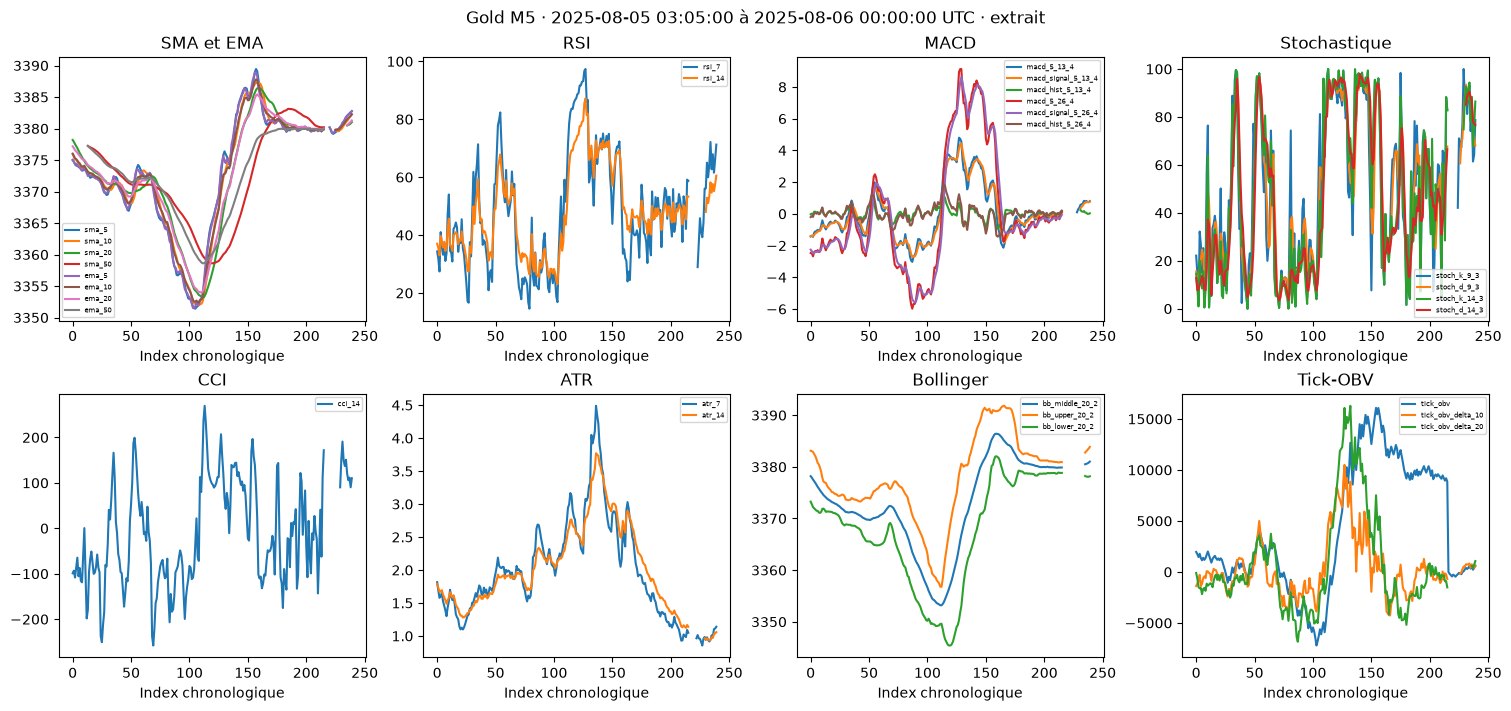

Les valeurs manquantes tiennent compte des fenêtres, des interruptions et des statuts Silver.


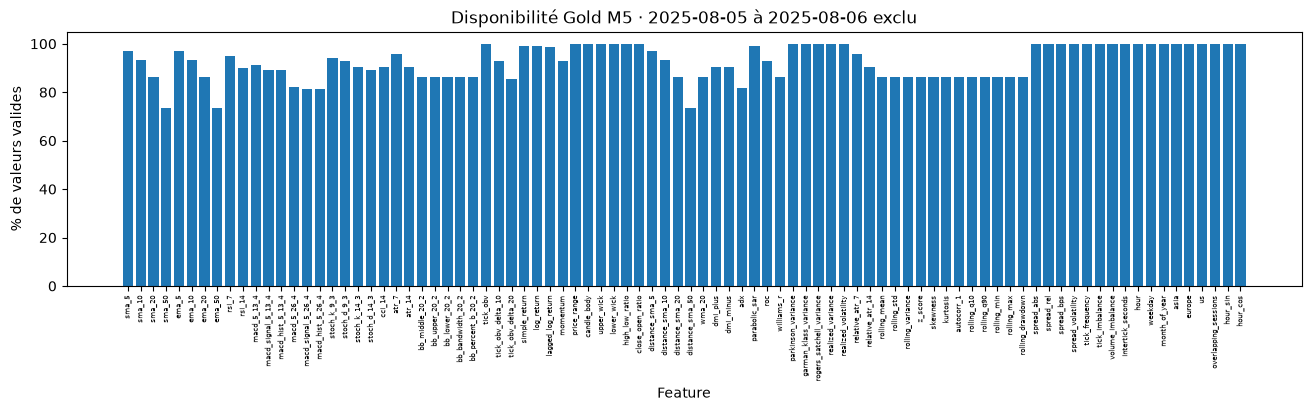

('Tendance', 'moyenne des clôtures', '5', 'mid_close', 'USD/once', 5) dernière valeur 3382.7306 mesures {'count': 268, 'null': 8, 'nan': 0, 'inf': 0, 'avg': 3373.8691858208954, 'min': 3351.4131, 'max': 3389.4523999999997, 'variance': 79.58517742860191, 'std': 8.921052484354181, 'quantiles': [3351.6807, 3353.6256000000003, 3369.7050000000004, 3375.5759, 3380.1812, 3385.4962, 3388.9824], 'skew': -0.8973616682679666, 'kurtosis': 0.13434692817648752, 'availability': 0.9710144927536232, 'constant': False}
('Tendance', 'EMA alpha=2/(n+1); amorce SMA', '5', 'mid_close', 'USD/once', 5) dernière valeur 3382.7789013018823 mesures {'count': 268, 'null': 8, 'nan': 0, 'inf': 0, 'avg': 3373.8763194521266, 'min': 3351.4903504228787, 'max': 3388.9301975205917, 'variance': 78.70897757360865, 'std': 8.871808021683554, 'quantiles': [3351.805900281919, 3353.877999348101, 3369.76039009803, 3375.160097734367, 3380.1634124570564, 3385.374421796994, 3388.312298347061], 'skew': -0.8984968751608913, 'kurtosis':

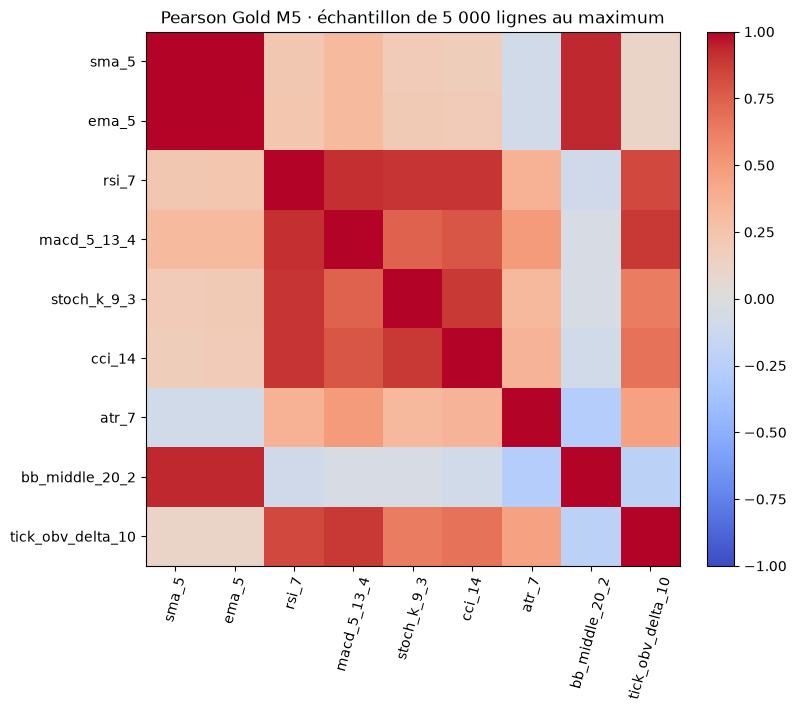

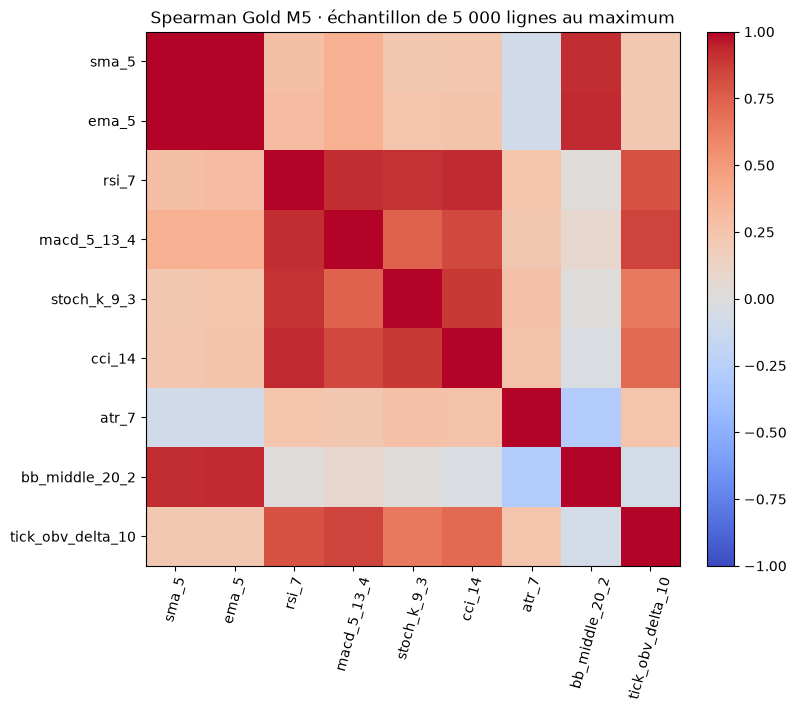

Ces corrélations utilisent les mêmes lignes complètes avec rang moyen en cas d’égalité.


Métriques Spark UI {'stages': 612, 'numTasks': 1060, 'numFailedTasks': 0, 'executorCpuTime': 36464319900, 'jvmGcTime': 1201, 'shuffleReadBytes': 2002475, 'shuffleWriteBytes': 2002475, 'diskBytesSpilled': 0, 'memoryBytesSpilled': 0}
gold {'run_key': 'ee7d454dc8a8024283ce25788d6c720a150a9dff959e8e744b38fa8cedae016a', 'status': 'complete', 'elapsed_run_seconds': 42.89, 'features': 88, 'timeframes': ['M1', 'M5', 'M15', 'M30', 'H1', 'H4', 'D1', 'W1', 'MN1']}
causality {'run_key': 'ee7d454dc8a8024283ce25788d6c720a150a9dff959e8e744b38fa8cedae016a', 'status': 'complete', 'elapsed_run_seconds': 43.045, 'mutated_future': True, 'gap_reset': True, 'partition_boundary': True}
catalogue_features {'run_key': 'ee7d454dc8a8024283ce25788d6c720a150a9dff959e8e744b38fa8cedae016a', 'status': 'complete', 'elapsed_run_seconds': 52.969, 'records': 792}


In [9]:
def gold_diagnostics():
    import matplotlib.pyplot as plt
    for tf in CFG['timeframes']:
        name=f'gold_profile_{tf}'
        if not completed(name):
            frame=require(f'gold_{tf}',GOLD/tf)
            summary={}
            for offset in range(0,len(FEATURES),12):
                keys=FEATURES[offset:offset+12]
                expr=[]
                for key in keys:
                    x=F.col(key)
                    invalid=x.isNull()|F.isnan(x)|(F.abs(x)==F.lit(float('inf')))
                    value=F.when(~invalid,x)
                    expr.extend([
                        F.count(value).alias(f'{key}__count'),
                        F.count_if(x.isNull()).alias(f'{key}__null'),
                        F.count_if(F.isnan(x)).alias(f'{key}__nan'),
                        F.count_if(F.abs(x)==F.lit(float('inf'))).alias(f'{key}__inf'),
                        F.avg(value).alias(f'{key}__avg'),F.min(value).alias(f'{key}__min'),
                        F.max(value).alias(f'{key}__max'),F.var_pop(value).alias(f'{key}__variance'),
                        F.stddev_pop(value).alias(f'{key}__std'),
                        F.percentile_approx(value,[.01,.05,.25,.50,.75,.95,.99],1000).alias(f'{key}__quantiles'),
                        F.skewness(value).alias(f'{key}__skew'),F.kurtosis(value).alias(f'{key}__kurtosis')])
                for key,value in frame.agg(*expr).first().asDict().items():
                    feature,metric=key.rsplit('__',1)
                    if isinstance(value,float) and not math.isfinite(value):
                        value=None
                    summary.setdefault(feature,{})[metric]=value
            assert sum(m['nan']+m['inf'] for m in summary.values())==0
            total=manifest(f'gold_{tf}')['rows']
            for rec in summary.values():
                assert rec['count']+rec['null']==total
                rec['availability']=rec['count']/total
                rec['constant']=rec['count']>0 and rec['min']==rec['max']
            put_json(reports/f'gold_profile_{tf}.json',summary)
            finish(name,rows=total,features=len(summary))
    tf=CFG['main']
    frame=require(f'gold_{tf}',GOLD/tf)
    rows=frame.orderBy(F.desc('available_at')).limit(240).collect()[::-1]
    panels=[('SMA et EMA',('sma_','ema_')),('RSI',('rsi_',)),('MACD',('macd_',)),
            ('Stochastique',('stoch_',)),('CCI',('cci_',)),('ATR',('atr_',)),
            ('Bollinger',('bb_middle_','bb_upper_','bb_lower_')),('Tick-OBV',('tick_obv',))]
    fig,axes=plt.subplots(2,4,figsize=(15,7),layout='constrained')
    for ax,(title,prefixes) in zip(axes.flat,panels):
        for key in (key for key in FEATURES if key.startswith(prefixes)):
            ax.plot([r[key] for r in rows],label=key)
        ax.set(title=title,xlabel='Index chronologique')
        ax.legend(fontsize=5)
    fig.suptitle(f'Gold {tf} · {rows[0].available_at} à {rows[-1].available_at} UTC · extrait')
    display(fig)
    plt.close(fig)
    print('Les valeurs manquantes tiennent compte des fenêtres, des interruptions et des statuts Silver.')

    summary=read_json(reports/f'gold_profile_{tf}.json',{})
    fig,ax=plt.subplots(figsize=(13,4),layout='constrained')
    ax.bar(range(len(FEATURES)),[100*summary[key]['availability'] for key in FEATURES])
    ax.set(title=f'Disponibilité Gold {tf} · {start} à {end} exclu',xlabel='Feature',ylabel='% de valeurs valides',
           xticks=range(len(FEATURES)),xticklabels=FEATURES,ylim=(0,105))
    ax.tick_params(axis='x',rotation=90,labelsize=5)
    display(fig)
    plt.close(fig)
    for key in ('sma_5','ema_5','rsi_7','macd_5_13_4','stoch_k_9_3','cci_14',
                'atr_7','bb_middle_20_2','tick_obv_delta_10'):
        print(feature_desc(key), 'dernière valeur', rows[-1][key], 'mesures', summary[key])
    keys=list(dict.fromkeys(x for x in ('sma_5','ema_5','rsi_7','macd_5_13_4','stoch_k_9_3','cci_14',
                                        'atr_7','bb_middle_20_2','tick_obv_delta_10') if summary[x]['count']))
    if keys:
        sample=(frame.select('available_at',*keys).dropna(subset=keys)
                .orderBy(F.xxhash64('available_at'),F.col('available_at')).limit(5000))
        ranked=sample
        for i,key in enumerate(keys):
            ranked=ranked.withColumn(f'_rank_{i}',F.rank().over(Window.orderBy(key))+
                                    (F.count('*').over(Window.partitionBy(key))-1)/2)
        for label,prefix in [('Pearson',False),('Spearman',True)]:
            cols=[f'_rank_{i}' for i in range(len(keys))] if prefix else keys
            values=ranked.agg(*[F.corr(a,b).alias(f'{i}_{j}') for i,a in enumerate(cols)
                                for j,b in enumerate(cols)]).first().asDict()
            fig,ax=plt.subplots(figsize=(8,7),layout='constrained')
            image=ax.imshow([[v if v is not None else math.nan for v in
                               (values[f'{i}_{j}'] for j in range(len(keys)))] for i in range(len(keys))],
                             vmin=-1,vmax=1,cmap='coolwarm')
            ax.set(title=f'{label} Gold {tf} · échantillon de 5 000 lignes au maximum',
                   xticks=range(len(keys)),xticklabels=keys,yticks=range(len(keys)),yticklabels=keys)
            ax.tick_params(axis='x',rotation=75)
            fig.colorbar(image)
            display(fig)
            plt.close(fig)
        print('Ces corrélations utilisent les mêmes lignes complètes avec rang moyen en cas d’égalité.')

if active('18') and completed('gold'):
    gold_diagnostics()
else:
    print('Statistiques et figures Gold réservées aux résultats compatibles.')
stage_report()